# Day 043 | Gradient Boosting & XGBoost
## 100 Days of ML for Geotechnical Engineering
**Phase:** Classical Machine Learning

**Author:** Ripon Chandra Malo  
**Date:** 2026-05-16  

---

## What We Will Learn Today

| Concept | What It Means | Geotechnical Example |
|---------|--------------|---------------------|
| Boosting | Sequentially fix previous mistakes | Each new engineer focuses on the sites where predictions were worst |
| Gradient Boosting | Fit trees to residual errors | Predict settlement error, then correct it iteratively |
| Learning rate | How much each tree contributes | Cautious corrections (0.01) vs aggressive fixes (1.0) |
| XGBoost | Optimized gradient boosting | Industry-standard tool for tabular geotechnical data |
| Boosting vs Bagging | Sequential vs parallel ensembles | Compare two team strategies for site assessment |
| Feature importance | Which inputs drive settlement | Is clay thickness or load pressure more critical? |

---

## Our Geotechnical Problem

A geotechnical engineer needs to predict **ground settlement** (mm) under applied loads based on:

- **Load pressure** (kPa)
- **Footing width** (m)
- **N-value** from SPT testing
- **Compression index** (Cc)
- **Void ratio** (e0)
- **Clay thickness** (m)

Settlement prediction is critical for ensuring structures don't experience excessive deformation. Today we use **boosting** — an approach that learns from its mistakes.

---

## Part 1: Generate Settlement Data

In [1]:
# ─────────────────────────────────────────────────────
# IMPORTS
# ─────────────────────────────────────────────────────

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

np.random.seed(42)
print("All imports successful.")

All imports successful.


In [2]:
# ─────────────────────────────────────────────────────
# GENERATE SETTLEMENT DATA
# ─────────────────────────────────────────────────────

n_samples = 100

load_pressure = np.round(np.random.uniform(50, 400, n_samples), 1)
footing_width = np.round(np.random.uniform(1.0, 5.0, n_samples), 2)
N_value = np.random.randint(5, 45, n_samples)
compression_index = np.round(np.random.uniform(0.1, 0.8, n_samples), 3)
void_ratio = np.round(np.random.uniform(0.4, 1.5, n_samples), 2)
clay_thickness = np.round(np.random.uniform(1.0, 15.0, n_samples), 1)

# Settlement formula inspired by consolidation theory:
# S = (Cc / (1 + e0)) * H * log10(1 + delta_sigma / sigma_0)
# Simplified with SPT correlation
sigma_0 = 50 + clay_thickness * 9  # approximate overburden
settlement = (
    (compression_index / (1 + void_ratio))
    * clay_thickness * 1000  # convert to mm
    * np.log10(1 + load_pressure / sigma_0)
    * (1 - 0.01 * N_value)  # SPT correction
    * (footing_width / 3.0) ** 0.5  # width effect
)
# Add noise (15% CoV)
noise = np.random.normal(0, 0.15 * np.abs(settlement))
settlement = np.round(np.maximum(settlement + noise, 1.0), 1)

df = pd.DataFrame({
    'load_pressure': load_pressure,
    'footing_width': footing_width,
    'N_value': N_value,
    'compression_index': compression_index,
    'void_ratio': void_ratio,
    'clay_thickness': clay_thickness,
    'settlement_mm': settlement
})

print(f"Dataset shape: {df.shape}")
print(f"\nSettlement range: {df['settlement_mm'].min():.1f} - {df['settlement_mm'].max():.1f} mm")
print(f"Mean settlement: {df['settlement_mm'].mean():.1f} mm")
print(f"\nFirst 5 rows:")
df.head()

Dataset shape: (100, 7)

Settlement range: 40.7 - 1934.0 mm
Mean settlement: 513.4 mm

First 5 rows:


,load_pressure,footing_width,N_value,compression_index,void_ratio,clay_thickness,settlement_mm
0,181.1,1.13,28,0.505,1.43,14.9,336.9
1,382.8,3.55,15,0.407,0.44,10.8,1428.5
2,306.2,2.26,12,0.570,0.86,6.4,637.2
3,259.5,3.03,40,0.330,1.46,11.3,450.2
4,104.6,4.63,42,0.209,1.00,13.8,143.0


In [3]:
# ─────────────────────────────────────────────────────
# EXPLORE FEATURE CORRELATIONS
# ─────────────────────────────────────────────────────

print("Correlation with settlement:")
print("=" * 40)
corr = df.corr()['settlement_mm'].drop('settlement_mm').sort_values(key=abs, ascending=False)
for feat, val in corr.items():
    bar = '+' * int(abs(val) * 30)
    print(f"  {feat:<22s}: {val:+.3f} |{bar}")

print(f"\nCompression index and clay thickness show the strongest correlations.")
print(f"N-value has a negative correlation (stiffer soil = less settlement).")

Correlation with settlement:
  load_pressure         : +0.518 |+++++++++++++++
  compression_index     : +0.512 |+++++++++++++++
  clay_thickness        : +0.437 |+++++++++++++
  footing_width         : +0.228 |++++++
  N_value               : -0.155 |++++
  void_ratio            : -0.079 |++

Compression index and clay thickness show the strongest correlations.
N-value has a negative correlation (stiffer soil = less settlement).


---

## Part 2: How Gradient Boosting Works

Unlike Random Forest (bagging = parallel), boosting is **sequential**:

1. **Tree 1**: Fit to the original target (settlement)
2. **Calculate residuals**: errors = actual - Tree 1 prediction
3. **Tree 2**: Fit to the residuals (learn from mistakes)
4. **Update**: prediction = Tree 1 + learning_rate × Tree 2
5. **Repeat**: Each new tree corrects the remaining errors

**Key difference from Random Forest:**
- Bagging: many trees in parallel, each sees random data
- Boosting: trees in sequence, each fixes previous errors

**Learning rate** (η) controls the contribution of each tree:
- Small η (0.01-0.1): Slow learning, needs more trees, but generalizes better
- Large η (0.5-1.0): Fast learning, fewer trees, but can overfit

In [4]:
# ─────────────────────────────────────────────────────
# DEMONSTRATE BOOSTING STEP BY STEP
# ─────────────────────────────────────────────────────

feature_cols = ['load_pressure', 'footing_width', 'N_value',
                'compression_index', 'void_ratio', 'clay_thickness']
X = df[feature_cols]
y = df['settlement_mm']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Manual boosting with 3 shallow trees
learning_rate = 0.5
current_pred = np.zeros(len(y_train))

print("Manual Boosting: 3 Rounds")
print("=" * 60)

for i in range(3):
    residuals = y_train.values - current_pred
    tree = DecisionTreeRegressor(max_depth=3, random_state=42)
    tree.fit(X_train, residuals)
    correction = tree.predict(X_train)
    current_pred += learning_rate * correction

    rmse = np.sqrt(mean_squared_error(y_train, current_pred))
    print(f"  Round {i+1}: RMSE = {rmse:.2f} mm  "
          f"(residual range: {residuals.min():.1f} to {residuals.max():.1f})")

print(f"\nEach tree reduces the error by learning from remaining residuals.")

Manual Boosting: 3 Rounds
  Round 1: RMSE = 366.99 mm  (residual range: 40.7 to 1934.0)
  Round 2: RMSE = 228.05 mm  (residual range: -73.1 to 1395.1)
  Round 3: RMSE = 145.15 mm  (residual range: -203.8 to 789.3)

Each tree reduces the error by learning from remaining residuals.


---

## Part 3: Train Gradient Boosting Regressor

In [5]:
# ─────────────────────────────────────────────────────
# GRADIENT BOOSTING REGRESSOR
# ─────────────────────────────────────────────────────

gb = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=4,
    random_state=42
)
gb.fit(X_train, y_train)
y_pred_gb = gb.predict(X_test)

print("Gradient Boosting Regressor")
print("=" * 40)
print(f"  R\u00b2 (train): {gb.score(X_train, y_train):.4f}")
print(f"  R\u00b2 (test):  {r2_score(y_test, y_pred_gb):.4f}")
print(f"  RMSE:       {np.sqrt(mean_squared_error(y_test, y_pred_gb)):.2f} mm")
print(f"  MAE:        {mean_absolute_error(y_test, y_pred_gb):.2f} mm")

Gradient Boosting Regressor
  R² (train): 1.0000
  R² (test):  0.9114
  RMSE:       137.71 mm
  MAE:        104.65 mm


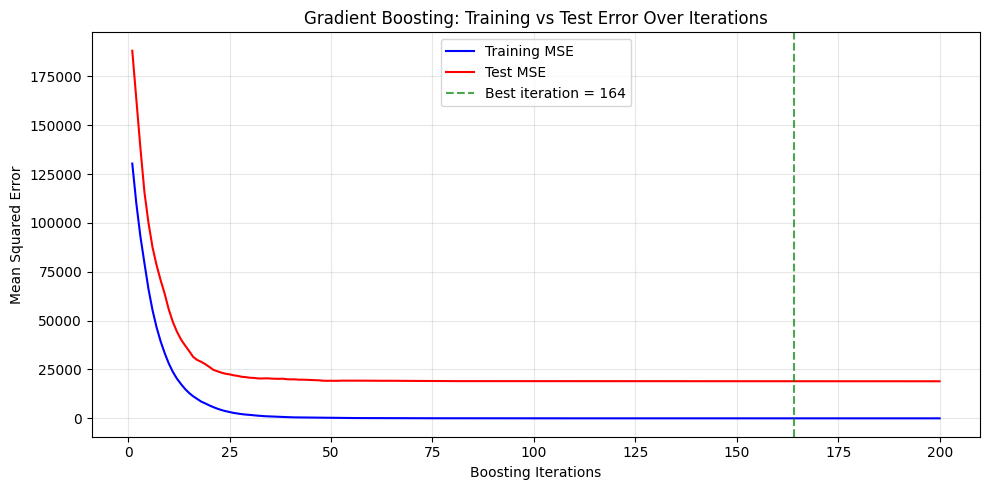

Best test MSE at iteration 164 of 200.
After that point, the model starts overfitting (test error rises).
This is a key difference from Random Forest, where more trees never hurt.


In [6]:
# ─────────────────────────────────────────────────────
# TRAINING ERROR vs ITERATIONS (STAGED PREDICTION)
# ─────────────────────────────────────────────────────

train_errors = []
test_errors = []

for i, y_pred_staged in enumerate(gb.staged_predict(X_train)):
    train_errors.append(mean_squared_error(y_train, y_pred_staged))

for i, y_pred_staged in enumerate(gb.staged_predict(X_test)):
    test_errors.append(mean_squared_error(y_test, y_pred_staged))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(range(1, len(train_errors) + 1), train_errors, 'b-', label='Training MSE')
ax.plot(range(1, len(test_errors) + 1), test_errors, 'r-', label='Test MSE')
best_iter = np.argmin(test_errors) + 1
ax.axvline(x=best_iter, color='green', linestyle='--', alpha=0.7,
           label=f'Best iteration = {best_iter}')
ax.set_xlabel('Boosting Iterations')
ax.set_ylabel('Mean Squared Error')
ax.set_title('Gradient Boosting: Training vs Test Error Over Iterations')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Best test MSE at iteration {best_iter} of {gb.n_estimators}.")
print(f"After that point, the model starts overfitting (test error rises).")
print(f"This is a key difference from Random Forest, where more trees never hurt.")

---

## Part 4: Compare with Random Forest

In [7]:
# ─────────────────────────────────────────────────────
# GRADIENT BOOSTING vs RANDOM FOREST vs DECISION TREE
# ─────────────────────────────────────────────────────

# Single Decision Tree
dt = DecisionTreeRegressor(max_depth=5, random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

# Random Forest
rf = RandomForestRegressor(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

models = {
    'Decision Tree': y_pred_dt,
    'Random Forest': y_pred_rf,
    'Gradient Boosting': y_pred_gb
}

print("Model Comparison for Settlement Prediction")
print("=" * 60)
print(f"{'Model':<22s} {'R\u00b2':>8s} {'RMSE (mm)':>10s} {'MAE (mm)':>10s}")
print("-" * 60)
for name, pred in models.items():
    r2 = r2_score(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    mae = mean_absolute_error(y_test, pred)
    print(f"{name:<22s} {r2:>8.4f} {rmse:>10.2f} {mae:>10.2f}")

Model Comparison for Settlement Prediction
Model                        R²  RMSE (mm)   MAE (mm)
------------------------------------------------------------
Decision Tree            0.6592     270.12     180.58
Random Forest            0.8631     171.21     140.66
Gradient Boosting        0.9114     137.71     104.65


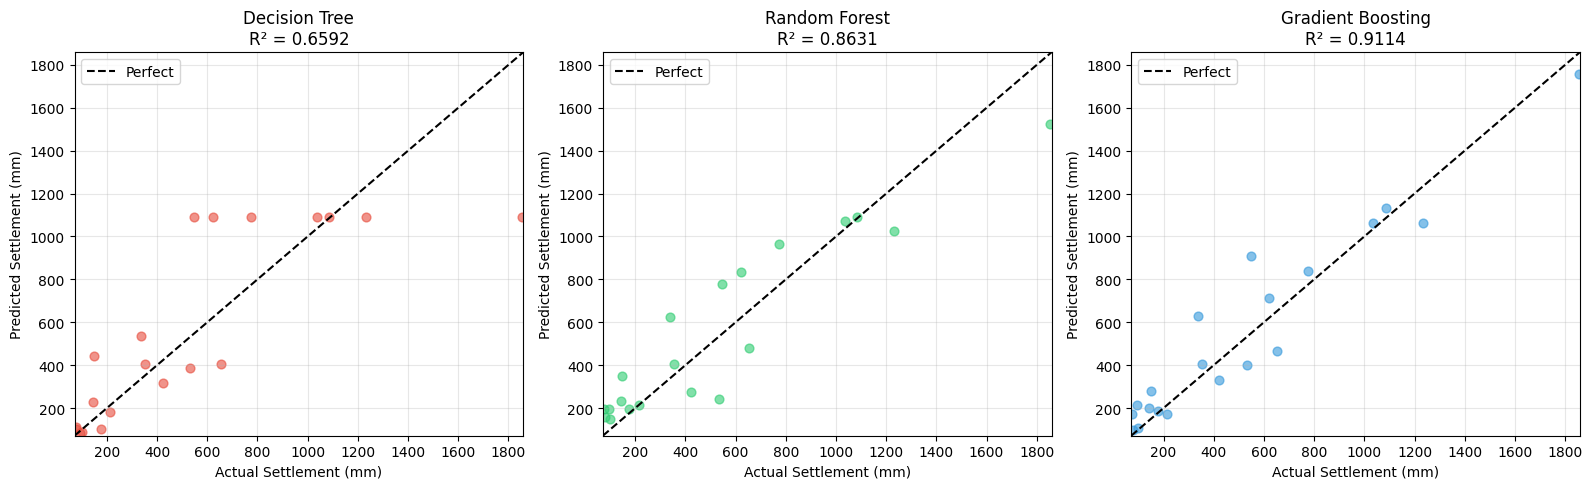

In [8]:
# ─────────────────────────────────────────────────────
# PREDICTED vs ACTUAL FOR ALL THREE MODELS
# ─────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
colors = ['#e74c3c', '#2ecc71', '#3498db']

for ax, (name, pred), color in zip(axes, models.items(), colors):
    ax.scatter(y_test, pred, alpha=0.6, s=40, color=color)
    lims = [min(y_test.min(), pred.min()) - 5, max(y_test.max(), pred.max()) + 5]
    ax.plot(lims, lims, 'k--', label='Perfect')
    ax.set_xlabel('Actual Settlement (mm)')
    ax.set_ylabel('Predicted Settlement (mm)')
    ax.set_title(f'{name}\nR\u00b2 = {r2_score(y_test, pred):.4f}')
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_xlim(lims)
    ax.set_ylim(lims)

plt.tight_layout()
plt.show()

---

## Part 5: XGBoost

In [9]:
# ─────────────────────────────────────────────────────
# XGBOOST REGRESSOR
# ─────────────────────────────────────────────────────

try:
    from xgboost import XGBRegressor
    xgb_available = True
except ImportError:
    print("XGBoost not installed. Install with: pip install xgboost")
    print("Continuing with sklearn's GradientBoostingRegressor as a proxy.")
    xgb_available = False

if xgb_available:
    xgb = XGBRegressor(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=4,
        random_state=42,
        verbosity=0
    )
    xgb.fit(X_train, y_train)
    y_pred_xgb = xgb.predict(X_test)

    print("XGBoost Regressor")
    print("=" * 40)
    print(f"  R\u00b2 (test):  {r2_score(y_test, y_pred_xgb):.4f}")
    print(f"  RMSE:       {np.sqrt(mean_squared_error(y_test, y_pred_xgb)):.2f} mm")
    print(f"  MAE:        {mean_absolute_error(y_test, y_pred_xgb):.2f} mm")
    print(f"\nComparison:")
    print(f"  Gradient Boosting R\u00b2: {r2_score(y_test, y_pred_gb):.4f}")
    print(f"  XGBoost R\u00b2:           {r2_score(y_test, y_pred_xgb):.4f}")
    print(f"\nXGBoost adds L1/L2 regularization and is optimized for speed.")

XGBoost Regressor
  R² (test):  0.9031
  RMSE:       144.04 mm
  MAE:        108.03 mm

Comparison:
  Gradient Boosting R²: 0.9114
  XGBoost R²:           0.9031

XGBoost adds L1/L2 regularization and is optimized for speed.


---

## Part 6: Feature Importance Comparison

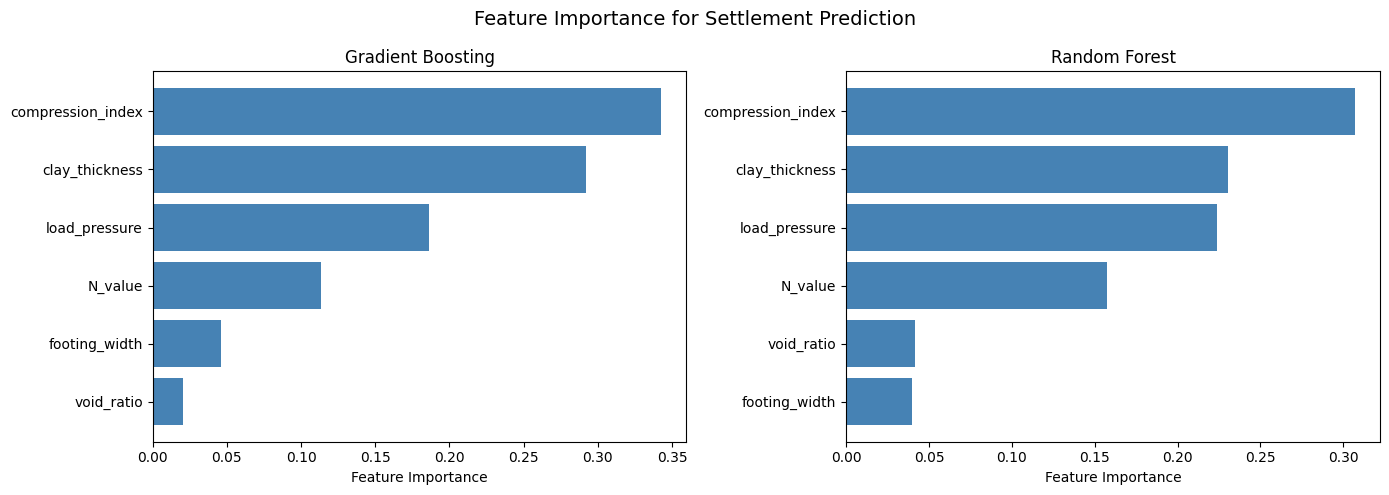

Feature Importance Rankings:
Feature                 Grad. Boost Random Forest
-------------------------------------------------------
load_pressure                0.1863        0.2239
footing_width                0.0458        0.0399
N_value                      0.1133        0.1577
compression_index            0.3425        0.3068
void_ratio                   0.0204        0.0413
clay_thickness               0.2917        0.2304

Both models agree on the most important features,
but exact rankings can differ due to different learning strategies.


In [10]:
# ─────────────────────────────────────────────────────
# FEATURE IMPORTANCE: GRADIENT BOOSTING vs RANDOM FOREST
# ─────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, model, name in zip(axes, [gb, rf], ['Gradient Boosting', 'Random Forest']):
    imp = model.feature_importances_
    sorted_idx = np.argsort(imp)
    ax.barh([feature_cols[i] for i in sorted_idx], imp[sorted_idx], color='steelblue')
    ax.set_xlabel('Feature Importance')
    ax.set_title(f'{name}')

fig.suptitle('Feature Importance for Settlement Prediction', fontsize=14)
plt.tight_layout()
plt.show()

print("Feature Importance Rankings:")
print("=" * 55)
print(f"{'Feature':<22s} {'Grad. Boost':>12s} {'Random Forest':>13s}")
print("-" * 55)
for i, feat in enumerate(feature_cols):
    print(f"{feat:<22s} {gb.feature_importances_[i]:>12.4f} {rf.feature_importances_[i]:>13.4f}")

print(f"\nBoth models agree on the most important features,")
print(f"but exact rankings can differ due to different learning strategies.")

---

## Part 7: Effect of Learning Rate

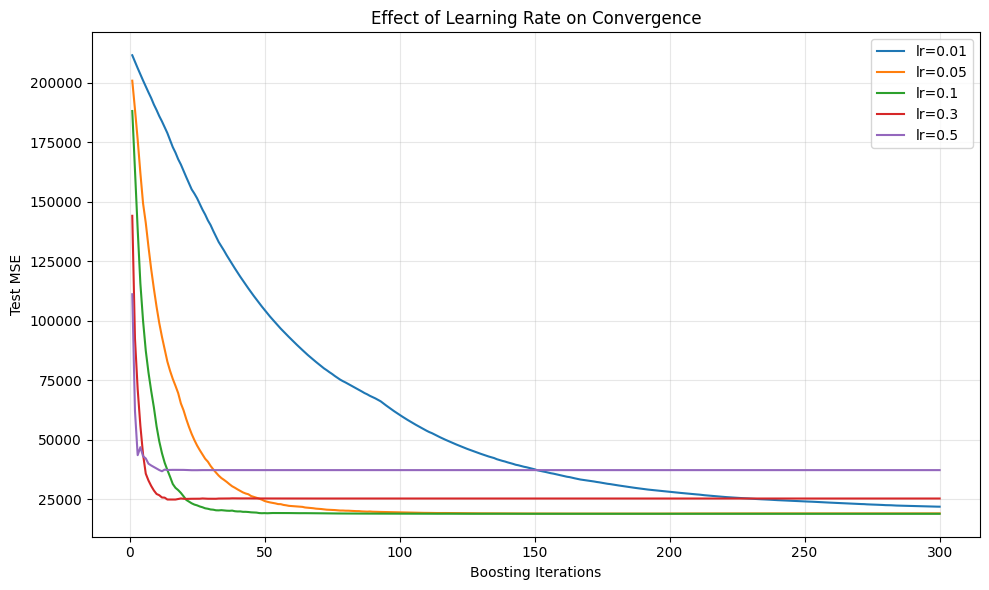

Observations:
  - Small learning rate (0.01): slow convergence, needs many iterations
  - Medium learning rate (0.1): good balance of speed and generalization
  - Large learning rate (0.5): fast convergence but overfits quickly

Best practice: use small lr with many trees (if compute allows).


In [11]:
# ─────────────────────────────────────────────────────
# LEARNING RATE vs NUMBER OF ITERATIONS
# ─────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(10, 6))

learning_rates = [0.01, 0.05, 0.1, 0.3, 0.5]
colors_lr = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

for lr, color in zip(learning_rates, colors_lr):
    gb_lr = GradientBoostingRegressor(
        n_estimators=300, learning_rate=lr, max_depth=4, random_state=42
    )
    gb_lr.fit(X_train, y_train)

    test_mse = [mean_squared_error(y_test, pred)
                for pred in gb_lr.staged_predict(X_test)]
    ax.plot(range(1, 301), test_mse, label=f'lr={lr}', color=color)

ax.set_xlabel('Boosting Iterations')
ax.set_ylabel('Test MSE')
ax.set_title('Effect of Learning Rate on Convergence')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Observations:")
print("  - Small learning rate (0.01): slow convergence, needs many iterations")
print("  - Medium learning rate (0.1): good balance of speed and generalization")
print("  - Large learning rate (0.5): fast convergence but overfits quickly")
print("\nBest practice: use small lr with many trees (if compute allows).")

---

## Part 8: Predict Settlement for New Sites

In [12]:
# ─────────────────────────────────────────────────────
# PREDICT SETTLEMENT FOR NEW SITES
# ─────────────────────────────────────────────────────

new_sites = pd.DataFrame({
    'load_pressure': [100, 250, 350],
    'footing_width': [2.0, 3.0, 4.0],
    'N_value': [30, 15, 8],
    'compression_index': [0.2, 0.5, 0.7],
    'void_ratio': [0.6, 1.0, 1.3],
    'clay_thickness': [3.0, 8.0, 12.0]
})

print("Settlement Predictions for New Sites")
print("=" * 70)

for i in range(len(new_sites)):
    row = new_sites.iloc[i]
    gb_pred = gb.predict(new_sites.iloc[[i]])[0]
    rf_pred = rf.predict(new_sites.iloc[[i]])[0]

    print(f"\nSite {i+1}: Load={row['load_pressure']:.0f}kPa, B={row['footing_width']:.1f}m, "
          f"N={row['N_value']:.0f}, Cc={row['compression_index']:.2f}")
    print(f"  Gradient Boosting: {gb_pred:.1f} mm")
    print(f"  Random Forest:     {rf_pred:.1f} mm")

print(f"\nSite 3 has the highest settlement \u2014 high load, thick soft clay,")
print(f"high Cc, low N-value. This matches engineering expectations.")

Settlement Predictions for New Sites

Site 1: Load=100kPa, B=2.0m, N=30, Cc=0.20
  Gradient Boosting: 69.7 mm
  Random Forest:     107.9 mm

Site 2: Load=250kPa, B=3.0m, N=15, Cc=0.50
  Gradient Boosting: 964.4 mm
  Random Forest:     728.5 mm

Site 3: Load=350kPa, B=4.0m, N=8, Cc=0.70
  Gradient Boosting: 1629.1 mm
  Random Forest:     1398.7 mm

Site 3 has the highest settlement — high load, thick soft clay,
high Cc, low N-value. This matches engineering expectations.


---

## Practice Exercises

### Exercise 1: Optimal Number of Trees
Use `staged_predict` to find the optimal number of boosting iterations for `learning_rate=0.05`. At what iteration does the test error stop improving?

### Exercise 2: XGBoost Regularization
If XGBoost is available, train models with `reg_alpha=0` vs `reg_alpha=1.0` (L1 regularization). Compare test RMSE. Does regularization help?

### Exercise 3: Subsample
Train Gradient Boosting with `subsample=0.8` (stochastic gradient boosting). Compare with `subsample=1.0`. Does random sampling help generalization?

In [13]:
# EXERCISE 1: Optimal iterations
# gb_slow = GradientBoostingRegressor(n_estimators=500, learning_rate=0.05, max_depth=4, random_state=42)
# gb_slow.fit(X_train, y_train)
# test_mse = [mean_squared_error(y_test, p) for p in gb_slow.staged_predict(X_test)]
# print(f"Best iteration: {np.argmin(test_mse)+1}, MSE: {min(test_mse):.2f}")

In [14]:
# EXERCISE 2: XGBoost regularization
# if xgb_available:
#     for alpha in [0, 0.1, 1.0, 10.0]:
#         xgb_reg = XGBRegressor(n_estimators=200, learning_rate=0.1, reg_alpha=alpha, random_state=42, verbosity=0)
#         xgb_reg.fit(X_train, y_train)
#         pred = xgb_reg.predict(X_test)
#         print(f"alpha={alpha:<5}: RMSE={np.sqrt(mean_squared_error(y_test, pred)):.2f}")

---

## Key Takeaways

1. **Gradient Boosting learns sequentially from mistakes**. Each tree fits the residual errors of the previous ensemble, gradually reducing the overall error.

2. **Learning rate controls the tradeoff** between convergence speed and generalization. Small learning rates (0.01-0.1) with many trees generally perform best.

3. **Unlike Random Forest, Gradient Boosting CAN overfit** with too many iterations. Monitor test error with `staged_predict` to find the sweet spot.

4. **XGBoost adds regularization and speed**. It includes L1/L2 penalties on leaf weights and uses optimized algorithms for faster training.

5. **Both boosting and bagging agree on feature importance**. Compression index, clay thickness, and load pressure drive settlement predictions.

---

## How This Connects to ML

| What We Did Today | ML Equivalent |
|-------------------|---------------|
| Settlement prediction | Regression with boosted ensembles |
| Sequential error correction | Gradient boosting algorithm |
| Learning rate tuning | Regularization via shrinkage |
| Staged predictions | Early stopping / iteration control |
| GB vs RF comparison | Boosting vs bagging ensembles |
| XGBoost | Industry-standard gradient boosting |
| Feature importance comparison | Model agreement / disagreement |

---

*Day 043 of 100 — Bagging reduces variance; boosting reduces bias. Together, they conquer!*